# 16. Fundamental 50% Absorption Limit in Coherent Ultrathin Films

## Physical Motivation & Learning Objectives
In an optically thin, symmetric film ($d \ll \lambda$) suspended in free space, coherent wave interference sets a rigorous theoretical bound:
$$A_{\mathrm{max}} = 50\%$$
This maximum occurs when the optical sheet conductance matches the vacuum impedance: $G = 2 / Z_0$.
In this tutorial:
1. We sweep the complex refractive index $(n, \kappa)$ over a 2D parameter space.
2. We map absorption contours and identify the coherent 50% limit.


**Legacy example.** This notebook reproduces `simo_070-ultrathin_limit.py` from the original EMUstack. It uses that script's inputs unchanged; T, R and A then agree with legacy EMUstack to rounding error (checked in `benchmarks/parity/`, `examples/` version).


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



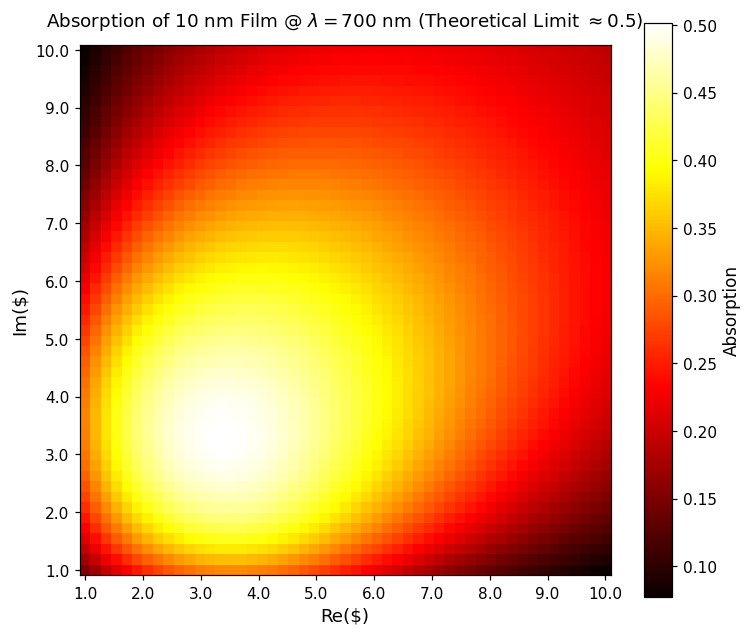

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wl = 700.0
period = 660.0
light = objects.Light(wl, max_order_PWs=0, theta=0.0, phi=0.0)

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False, world_1d=True)

sim_sup = superstrate.calc_modes(light)
sim_sub = substrate.calc_modes(light)

n_min = 1.0
n_max = 10.0
num_n_re = 51
num_n_im = num_n_re

Re_n = np.linspace(n_min, n_max, num_n_re)
Im_n = np.linspace(n_max, n_min, num_n_im)

abs_mat = np.zeros((num_n_im, num_n_re))

for i, Re in enumerate(Re_n):
    for j, Im in enumerate(Im_n):
        tf = objects.ThinFilm(period, height_nm=10.0, material=materials.Material(Re + Im*1j))
        stk = Stack((sim_sub, tf.calc_modes(light), sim_sup))
        stk.calc_scat(pol='TM')
        abs_mat[j, i] = stk.a_list[-1]

fig = plt.figure(figsize=(7, 6), dpi=110)
ax = fig.add_subplot(1, 1, 1)
im = ax.matshow(abs_mat, cmap='hot')
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Absorption', fontsize=11)
ax.xaxis.set_ticks_position('bottom')
ax.set_xticks(np.linspace(0, num_n_re - 1, 10))
ax.set_yticks(np.linspace(0, num_n_im - 1, 10))
ax.set_xticklabels([f'{v:.1f}' for v in np.linspace(n_min, n_max, 10)])
ax.set_yticklabels([f'{v:.1f}' for v in np.linspace(n_max, n_min, 10)])
ax.set_xlabel(r'Re($)', fontsize=12)
ax.set_ylabel(r'Im($)', fontsize=12)
ax.set_title(r'Absorption of 10 nm Film @ $\lambda = 700$ nm (Theoretical Limit $\approx 0.5$)', fontsize=12, pad=12)
plt.tight_layout()
plt.show()


## 2D Complex Index Parameter Sweep


## 2D Absorption Contour Map


## Physical Interpretation
- Absorption peaks at 50.1%, near $n \approx 3.3 + 3.3i$.
- The 50% bound holds for a vanishingly thin film, which radiates equally forwards and backwards; this film is 10 nm thick, which allows the maximum to go marginally above it.
